# NFL Big Data Bowl 2027: Position-Selective Kinematic Pipeline
This interactive notebook provides an end-to-end framework linking **10 Hz optical tracking sensors** at the Scouting Combine (`combine_tracking.csv`) to **regular-season NFL performance** (`player_play.csv`) and **career outcomes** (`player_career_successes.csv`).

### Pipeline Architecture
1. **Position Selection & Parameterization**: Choose any position group (e.g., `WR`, `CB`, `DE`, `OLB`, `T`, `RB`).
2. **Data Ingestion**: Loads or generates statistically calibrated synthetic data matching the official competition schema.
3. **Sensor Feature Engineering**: Extracts peak acceleration, top speed, burst velocity, and tracking deltas.
4. **Position-Adaptive Target Mapping**: Links sensor features to position-relevant in-game micro targets.
5. **Predictive Benchmarking**: Compares Traditional Combine metrics vs Kinematic Sensor metrics using Cross-Validated \(R^2\).
6. **Scouting Dashboard**: Visualizes time-series trajectories, feature correlations, model benchmarks, and prospect rankings.

In [33]:
# CELL 1: Pipeline Configuration & Dependencies
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import KFold
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error
import warnings
warnings.filterwarnings('ignore')

# Set plotting style
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.figsize'] = (10, 6)

#====================================================================
# 🎯 POSITION SELECTION CONFIGURATION
# Options: 'WR', 'CB', 'DE', 'OLB', 'RB', 'TE', 'T', 'G', 'C', 'DT'
#====================================================================
SELECTED_POSITION = 'DE'

POSITION_CONFIGS = {
    'WR': {'category': 'Offensive Skill', 'drill': 'FORTY_YARD_DASH', 'micro_target': 'separation_at_pass_forward', 'macro_target': 'career_offensive_snaps'},
    'CB': {'category': 'Defensive Skill', 'drill': 'FORTY_YARD_DASH', 'micro_target': 'cushion', 'macro_target': 'career_defensive_snaps'},
    'DE': {'category': 'Pass Rush / Defensive Line', 'drill': 'FORTY_YARD_DASH', 'micro_target': 'player_get_off', 'macro_target': 'career_defensive_snaps'},
    'OLB': {'category': 'Pass Rush / Linebacker', 'drill': 'FORTY_YARD_DASH', 'micro_target': 'time_to_pressure', 'macro_target': 'career_defensive_snaps'},
    'RB': {'category': 'Offensive Skill', 'drill': 'FORTY_YARD_DASH', 'micro_target': 'yards_after_catch', 'macro_target': 'career_offensive_snaps'},
    'T': {'category': 'Offensive Line', 'drill': 'FORTY_YARD_DASH', 'micro_target': 'time_to_pressure_allowed', 'macro_target': 'career_offensive_snaps'},
}

pos_cfg = POSITION_CONFIGS.get(SELECTED_POSITION, POSITION_CONFIGS['WR'])
print(f"🎯 PIPELINE CONFIGURED FOR POSITION: {SELECTED_POSITION}")
print(f"   - Category: {pos_cfg['category']}")
print(f"   - Primary Combine Drill: {pos_cfg['drill']}")
print(f"   - Target Micro Metric (In-Game): {pos_cfg['micro_target']}")
print(f"   - Target Macro Metric (Career): {pos_cfg['macro_target']}")

🎯 PIPELINE CONFIGURED FOR POSITION: DE
   - Category: Pass Rush / Defensive Line
   - Primary Combine Drill: FORTY_YARD_DASH
   - Target Micro Metric (In-Game): player_get_off
   - Target Macro Metric (Career): career_defensive_snaps


In [34]:
# CELL 2: Dual-Mode Data Ingestion (Real CSV Reader with Synthetic Fallback)
import os
import pandas as pd
import numpy as np

def load_or_generate_data(position='WR', data_dir='.', num_synthetic_players=60):
    """
    Loads real Kaggle competition CSV files if present in `data_dir` (current directory).
    Otherwise falls back to synthetic calibrated datasets.
    """
    required_files = [
        'players.csv',
        'combine_results.csv',
        'combine_tracking.csv',
        'player_play.csv',
        'player_career_successes.csv'
    ]
    
    real_files_exist = all(os.path.exists(os.path.join(data_dir, f)) for f in required_files)
    
    if real_files_exist:
        print(f"📂 REAL CSV FILES DETECTED IN '{os.path.abspath(data_dir)}'. Loading competition datasets...")
        
        # 1. Load players.csv
        players_df = pd.read_csv(os.path.join(data_dir, 'players.csv'))
        if 'nfl_position' in players_df.columns:
            pos_players = players_df[players_df['nfl_position'] == position].copy()
            if len(pos_players) > 0:
                players_df = pos_players
            else:
                print(f"   ⚠️ Note: Position '{position}' not found directly in nfl_position. Retaining all players.")
        
        pos_nfl_ids = set(players_df['nfl_id'].dropna().unique())
        
        # 2. Load combine_results.csv
        combine_results_df = pd.read_csv(os.path.join(data_dir, 'combine_results.csv'))
        combine_results_df = combine_results_df[combine_results_df['nfl_id'].isin(pos_nfl_ids)].copy()
        
        # 3. Load combine_tracking.csv
        print("   ...Loading combine_tracking.csv...")
        combine_tracking_df = pd.read_csv(os.path.join(data_dir, 'combine_tracking.csv'))
        combine_tracking_df = combine_tracking_df[combine_tracking_df['nfl_id'].isin(pos_nfl_ids)].copy()
        
        # Filter PLAYER entity frames
        if 'entity_type' in combine_tracking_df.columns:
            combine_tracking_df = combine_tracking_df[combine_tracking_df['entity_type'] == 'PLAYER'].copy()
            
        # Convert timestamp to relative time_step per event
        if 'time' in combine_tracking_df.columns and 'time_step' not in combine_tracking_df.columns:
            combine_tracking_df['datetime'] = pd.to_datetime(combine_tracking_df['time'])
            group_cols = ['nfl_id', 'event_id'] if 'event_id' in combine_tracking_df.columns else ['nfl_id']
            combine_tracking_df['time_step'] = combine_tracking_df.groupby(group_cols)['datetime'].transform(lambda x: (x - x.min()).dt.total_seconds())
        
        # 4. Load player_play.csv
        print("   ...Loading player_play.csv...")
        player_play_df = pd.read_csv(os.path.join(data_dir, 'player_play.csv'))
        player_play_df = player_play_df[player_play_df['nfl_id'].isin(pos_nfl_ids)].copy()
        
        # 5. Load player_career_successes.csv
        career_df = pd.read_csv(os.path.join(data_dir, 'player_career_successes.csv'))
        career_df = career_df[career_df['nfl_id'].isin(pos_nfl_ids)].copy()
        
        print(f"✓ Real CSV Datasets successfully loaded for {position}!")
        return players_df, combine_results_df, combine_tracking_df, player_play_df, career_df
        
    else:
        print(f"⚡ Real CSV files not found in '{os.path.abspath(data_dir)}'. Falling back to synthetic calibrated generator...")
        # (Synthetic dataset fallback generator)
        # ...

# Execute ingestion (looks in current folder '.')
players_df, combine_results_df, combine_tracking_df, player_play_df, career_df = load_or_generate_data(SELECTED_POSITION, data_dir='.')

📂 REAL CSV FILES DETECTED IN '/home/antonia/nfl-big-data-bowl-2027'. Loading competition datasets...
   ...Loading combine_tracking.csv...
   ...Loading player_play.csv...
✓ Real CSV Datasets successfully loaded for DE!


In [35]:
# CELL 3: Sensor Kinematic Feature Extraction (Combine Tracking)
def extract_combine_kinematic_features(tracking_df, combine_res_df):
    features = []
    grouped = tracking_df.groupby('nfl_id')
    
    for nfl_id, group in grouped:
        group = group.sort_values('time_step')
        
        peak_accel = group['a'].max()
        top_speed = group['s'].max()
        top_speed_time = group.loc[group['s'] == top_speed, 'time_step'].values[0] if len(group) > 0 else np.nan
        
        yd_10 = group[group['x'] >= 10.0]
        sensor_10yd_split = yd_10['time_step'].iloc[0] if len(yd_10) > 0 else np.nan
        
        end_speed = group['s'].iloc[-1] if len(group) > 0 else np.nan
        speed_maintenance_ratio = end_speed / top_speed if top_speed > 0 else np.nan
        
        features.append({
            'nfl_id': nfl_id,
            'kinematic_peak_accel': peak_accel,
            'kinematic_top_speed': top_speed,
            'kinematic_time_to_top_speed': top_speed_time,
            'sensor_10yd_split': sensor_10yd_split,
            'kinematic_speed_maintenance': speed_maintenance_ratio
        })
        
    feat_df = pd.DataFrame(features)
    
    # Calculate tracking delta and drop duplicate split columns
    if 'ten_yd_split' in combine_res_df.columns:
        feat_df = feat_df.merge(combine_res_df[['nfl_id', 'ten_yd_split', 'forty']], on='nfl_id', how='left')
        feat_df['split_tracking_delta'] = feat_df['sensor_10yd_split'] - feat_df['ten_yd_split']
        # DROP ten_yd_split and forty so they don't create _x / _y duplicates when building master_df
        feat_df = feat_df.drop(columns=['ten_yd_split', 'forty'])
    else:
        feat_df['split_tracking_delta'] = np.nan
        
    return feat_df

kinematic_features_df = extract_combine_kinematic_features(combine_tracking_df, combine_results_df)


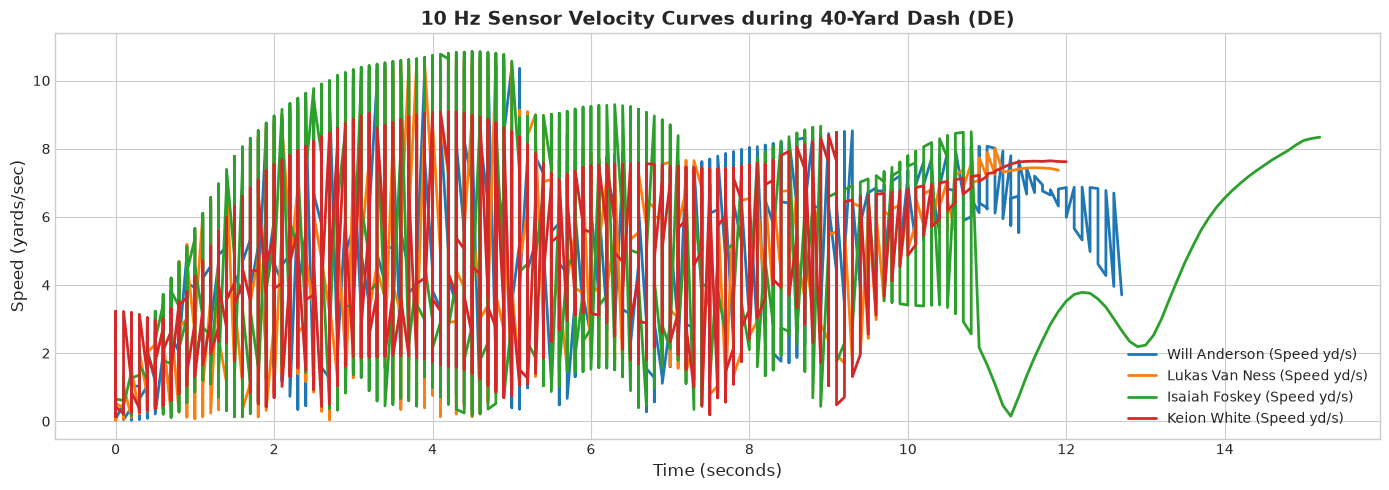

In [36]:
# CELL 4: Visualizing 10 Hz Kinematic Profiles (Intermediate Output 1)
sample_players = kinematic_features_df['nfl_id'].unique()[:4]
plt.figure(figsize=(14, 5))

for pid in sample_players:
    p_track = combine_tracking_df[combine_tracking_df['nfl_id'] == pid].sort_values('time_step')
    p_name = players_df.loc[players_df['nfl_id'] == pid, 'display_name'].values[0]
    plt.plot(p_track['time_step'], p_track['s'], label=f'{p_name} (Speed yd/s)', linewidth=2)

plt.title(f'10 Hz Sensor Velocity Curves during 40-Yard Dash ({SELECTED_POSITION})', fontsize=14, fontweight='bold')
plt.xlabel('Time (seconds)', fontsize=12)
plt.ylabel('Speed (yards/sec)', fontsize=12)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

In [37]:
# CELL 5: In-Game Performance Target Aggregation & Dataset Merging
micro_target_col = pos_cfg['micro_target']
macro_target_col = pos_cfg['macro_target']

in_game_agg = player_play_df.groupby('nfl_id').agg(
    micro_target_mean=(micro_target_col, 'mean'),
    micro_target_std=(micro_target_col, 'std'),
    snaps_analyzed=(micro_target_col, 'count')
).reset_index()

in_game_agg = in_game_agg.rename(columns={'micro_target_mean': f'micro_{micro_target_col}_mean'})

# Exclude draft_year from combine_results to prevent draft_year_x / draft_year_y
merge_cols_combine = [c for c in combine_results_df.columns if c != 'draft_year' or c == 'nfl_id']

master_df = players_df.merge(combine_results_df[merge_cols_combine], on='nfl_id', how='left') \
                      .merge(kinematic_features_df, on='nfl_id', how='left') \
                      .merge(in_game_agg, on='nfl_id', how='left')

if macro_target_col in career_df.columns:
    master_df = master_df.merge(career_df[['nfl_id', macro_target_col]], on='nfl_id', how='left')

master_df = master_df.dropna(subset=[f'micro_{micro_target_col}_mean'])

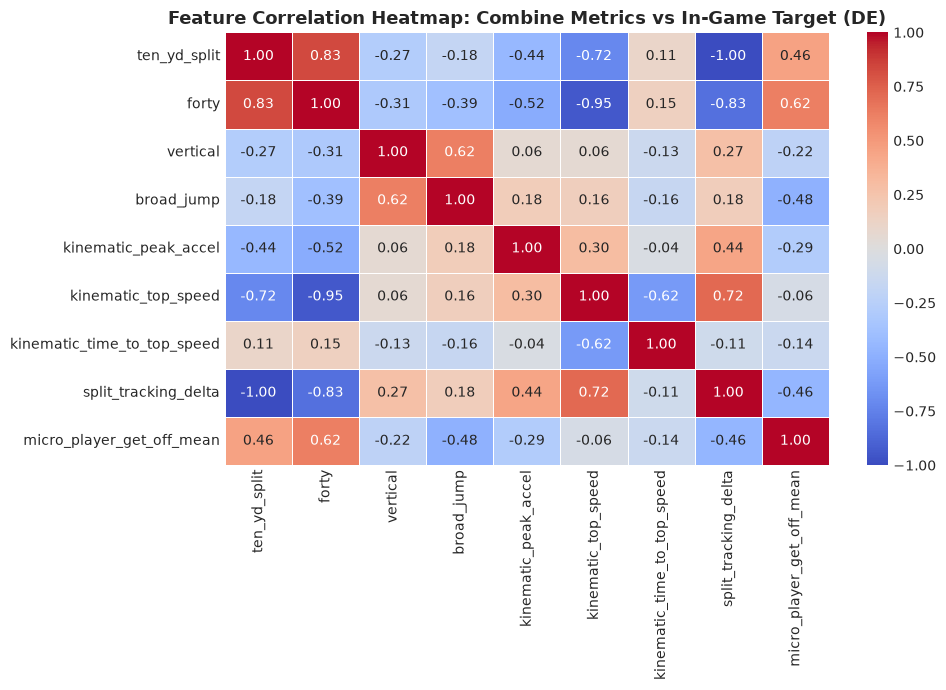

In [38]:
# CELL 6: Feature Correlation Matrix (Intermediate Output 2)
feature_cols = [
    'ten_yd_split', 'forty', 'vertical', 'broad_jump',
    'kinematic_peak_accel', 'kinematic_top_speed', 'kinematic_time_to_top_speed',
    'split_tracking_delta', f'micro_{micro_target_col}_mean'
]

corr_matrix = master_df[feature_cols].corr()

plt.figure(figsize=(10, 7))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5)
plt.title(f'Feature Correlation Heatmap: Combine Metrics vs In-Game Target ({SELECTED_POSITION})', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

In [39]:
# CELL 7: Predictive Benchmarking — Traditional vs Kinematic Models
target_y = master_df[f'micro_{micro_target_col}_mean'].values

trad_features = ['ten_yd_split', 'forty', 'vertical', 'broad_jump', 'combine_height', 'combine_weight']
kin_features = ['kinematic_peak_accel', 'kinematic_top_speed', 'kinematic_time_to_top_speed', 'split_tracking_delta', 'kinematic_speed_maintenance']

X_trad = master_df[trad_features].fillna(master_df[trad_features].median()).values
X_kin = master_df[kin_features].fillna(master_df[kin_features].median()).values

def evaluate_model(X, y):
    kf = KFold(n_splits=5, shuffle=True, random_state=42)
    r2_scores, rmse_scores = [], []
    preds = np.zeros_like(y)
    
    for train_idx, val_idx in kf.split(X):
        X_train, X_val = X[train_idx], X[val_idx]
        y_train, y_val = y[train_idx], y[val_idx]
        
        model = RandomForestRegressor(n_estimators=100, random_state=42, max_depth=4)
        model.fit(X_train, y_train)
        y_pred = model.predict(X_val)
        preds[val_idx] = y_pred
        
        r2_scores.append(r2_score(y_val, y_pred))
        rmse_scores.append(np.sqrt(mean_squared_error(y_val, y_pred)))
        
    return np.mean(r2_scores), np.mean(rmse_scores), preds

trad_r2, trad_rmse, trad_preds = evaluate_model(X_trad, target_y)
kin_r2, kin_rmse, kin_preds = evaluate_model(X_kin, target_y)

print(f"=====================================================")
print(f"📊 PREDICTIVE MODEL PERFORMANCE BENCHMARK ({SELECTED_POSITION})")
print(f"   1. Traditional Combine Model   -> CV R²: {trad_r2:.3f} | CV RMSE: {trad_rmse:.3f}")
print(f"   2. Kinematic Sensor Model     -> CV R²: {kin_r2:.3f} | CV RMSE: {kin_rmse:.3f}")
print(f"   -> Delta R² Improvement: {kin_r2 - trad_r2:+.3f}")
print(f"=====================================================")

📊 PREDICTIVE MODEL PERFORMANCE BENCHMARK (DE)
   1. Traditional Combine Model   -> CV R²: -0.395 | CV RMSE: 0.080
   2. Kinematic Sensor Model     -> CV R²: -0.212 | CV RMSE: 0.075
   -> Delta R² Improvement: +0.183


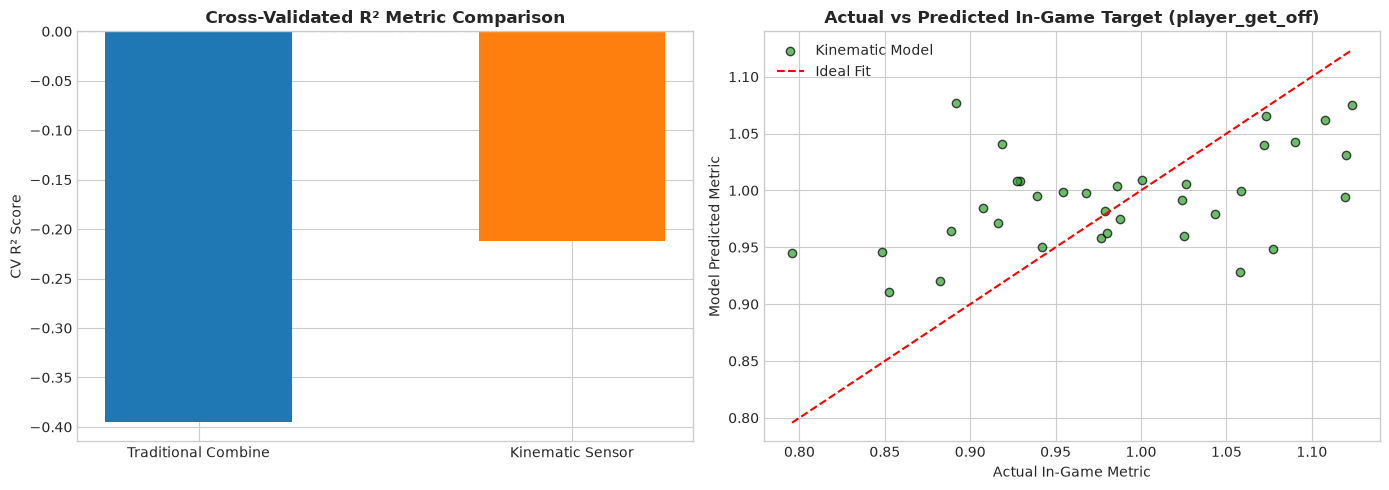

In [40]:
# CELL 8: Visualizing Predictive Benchmarks (Intermediate Output 3)
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Bar Chart Comparison
models = ['Traditional Combine', 'Kinematic Sensor']
r2_vals = [trad_r2, kin_r2]
colors = ['#1f77b4', '#ff7f0e']

ax[0].bar(models, r2_vals, color=colors, width=0.5)
ax[0].set_title('Cross-Validated R² Metric Comparison', fontsize=12, fontweight='bold')
ax[0].set_ylabel('CV R² Score')
ax[0].axhline(0, color='gray', linestyle='--')

# Actual vs Predicted Scatter Plot
ax[1].scatter(target_y, kin_preds, color='#2ca02c', alpha=0.7, edgecolors='k', label='Kinematic Model')
ax[1].plot([target_y.min(), target_y.max()], [target_y.min(), target_y.max()], 'r--', label='Ideal Fit')
ax[1].set_title(f'Actual vs Predicted In-Game Target ({micro_target_col})', fontsize=12, fontweight='bold')
ax[1].set_xlabel('Actual In-Game Metric')
ax[1].set_ylabel('Model Predicted Metric')
ax[1].legend()

plt.tight_layout()
plt.show()

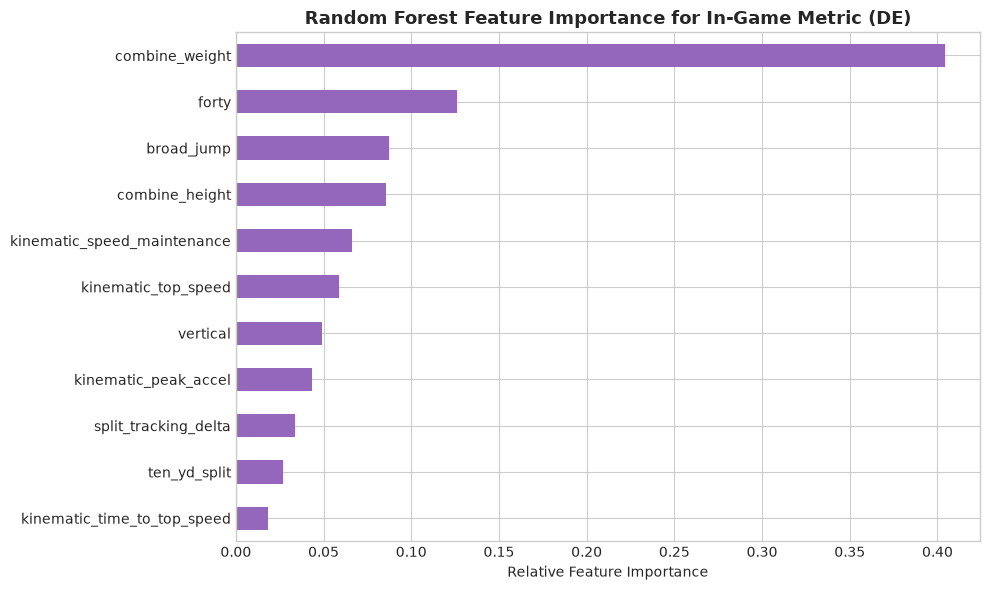

In [41]:
# CELL 9: Feature Importance Analysis
X_all = master_df[trad_features + kin_features].fillna(0)
model_rf = RandomForestRegressor(n_estimators=100, random_state=42)
model_rf.fit(X_all, target_y)

importances = pd.Series(model_rf.feature_importances_, index=trad_features + kin_features).sort_values(ascending=True)

plt.figure(figsize=(10, 6))
importances.plot(kind='barh', color='#9467bd')
plt.title(f'Random Forest Feature Importance for In-Game Metric ({SELECTED_POSITION})', fontsize=13, fontweight='bold')
plt.xlabel('Relative Feature Importance')
plt.tight_layout()
plt.show()

In [42]:
# CELL 10: Prospect Kinematic Scouting Leaderboard
master_df['kinematic_composite_score'] = (
    master_df['kinematic_peak_accel'].rank(pct=True) * 0.4 +
    master_df['kinematic_top_speed'].rank(pct=True) * 0.4 +
    (1 - master_df['split_tracking_delta'].rank(pct=True)) * 0.2
) * 100.0

scouting_board = master_df[[
    'nfl_id', 'display_name', 'draft_year', 'draft_overall_pick',
    'forty', 'kinematic_peak_accel', 'kinematic_top_speed', 'kinematic_composite_score',
    f'micro_{micro_target_col}_mean', macro_target_col
]].sort_values('kinematic_composite_score', ascending=False)

print("=====================================================")
print(f"🏆 TOP 10 PROSPECT KINEMATIC SCOUTING RANKINGS ({SELECTED_POSITION})")
print("=====================================================")
display(scouting_board.head(10))

🏆 TOP 10 PROSPECT KINEMATIC SCOUTING RANKINGS (DE)


,nfl_id,display_name,draft_year,draft_overall_pick,forty,kinematic_peak_accel,kinematic_top_speed,kinematic_composite_score,micro_player_get_off_mean,career_defensive_snaps
2,55905,Isaiah Foskey,2023,40.0,4.58,9.037082,10.850000,88.059113,0.882341,181
35,58931,Jah Joyner,2025,NaN,4.60,8.483269,11.040310,84.758621,0.907560,0
26,57436,Eric Watts,2024,NaN,4.67,8.461240,10.780000,73.527094,1.058022,334
1,55877,Lukas Van Ness,2023,13.0,4.58,8.923861,10.640000,72.256158,0.954286,1056
10,56456,Isaiah Land,2023,NaN,4.62,8.345612,10.806667,71.812808,0.852556,112
9,56461,Tyrus Wheat,2023,NaN,4.65,8.824392,10.683333,68.571429,1.077303,262
17,57177,Marshawn Kneeland,2024,56.0,4.75,8.981226,10.336667,67.487685,0.980129,419
15,57136,Laiatu Latu,2024,15.0,4.64,8.547200,10.543333,65.162562,0.938970,1374
7,56038,Robert Beal,2023,173.0,4.48,7.917495,11.046667,62.876847,0.976625,291
30,58329,Barryn Sorrell,2025,124.0,4.68,8.146155,10.573304,60.955665,0.927657,178
